# Лабораторная работа №2. Regularization и KNN

- **Часть A** — L1 / L2 / ElasticNet в линейной (Bike Sharing) и логистической (Spaceship Titanic) регрессии из ЛР1.
- **Часть B** — KNN-классификация, Dry Bean, target `Class`.
- **Часть C** — KNN-регрессия, Seoul Bike Sharing, target `Rented Bike Count`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_DIR = Path("../../data")
VAL_SIZE = 0.2
TEST_SIZE = 0.2
RANDOM_STATE = 42

## Общие инструменты

Собственный train/validation/test split и метрики.

In [2]:
def train_val_test_split_own(n_samples, val_size=0.2, test_size=0.2, random_state=42):
    # test — первый кусок перестановки: при том же seed совпадает с test из ЛР1
    rng = np.random.default_rng(random_state)
    shuffled = rng.permutation(n_samples)

    n_test = int(round(n_samples * test_size))
    n_val = int(round(n_samples * val_size))
    return shuffled[n_test + n_val:], shuffled[n_test:n_test + n_val], shuffled[:n_test]

In [3]:
def mae(y_true, y_pred):
    return float(np.mean(np.abs(y_true - y_pred)))


def rmse(y_true, y_pred):
    return float(np.sqrt(np.mean((y_true - y_pred) ** 2)))


def r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return float(1 - ss_res / ss_tot)


def accuracy(y_true, y_pred):
    return float(np.mean(y_true == y_pred))


def f1(y_true, y_pred):
    tp = np.sum((y_pred == 1) & (y_true == 1))
    fp = np.sum((y_pred == 1) & (y_true == 0))
    fn = np.sum((y_pred == 0) & (y_true == 1))
    return float(2 * tp / (2 * tp + fp + fn))


def log_loss(y_true, y_proba):
    y_proba = np.clip(y_proba, 1e-15, 1 - 1e-15)
    return float(-np.mean(y_true * np.log(y_proba) + (1 - y_true) * np.log(1 - y_proba)))

# Часть A. Regularization

К loss добавляется штраф за величину весов, к градиенту по весам — производная штрафа.
Bias не штрафуется. Все 4 варианта — один класс с параметрами `l1` и `l2`:

| вариант | штраф | добавка к `dw` |
|---|---|---|
| без регуляризации | 0 | 0 |
| L1 | λ₁·Σ\|w\| | λ₁·sign(w) |
| L2 | λ₂·Σw² | 2λ₂·w |
| ElasticNet | λ₁·Σ\|w\| + λ₂·Σw² | λ₁·sign(w) + 2λ₂·w |

## Модели с регуляризацией

In [4]:
def penalty(w, l1, l2):
    return l1 * np.sum(np.abs(w)) + l2 * np.sum(w ** 2)


def penalty_grad(w, l1, l2):
    return l1 * np.sign(w) + 2 * l2 * w

In [5]:
class LinearRegression:

    def __init__(self, learning_rate=0.05, epochs=10000, l1=0.0, l2=0.0):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.l1 = l1
        self.l2 = l2

        self.w = None
        self.b = None
        self.history_ = []  # MSE + штраф на train

    def fit(self, X, y):
        n_samples, n_features = X.shape

        self.w = np.zeros(n_features)
        self.b = 0.0
        self.history_ = []

        for _ in range(self.epochs):
            error = self.predict(X) - y
            self.history_.append(float(np.mean(error ** 2)) + penalty(self.w, self.l1, self.l2))

            dw = 2 / n_samples * (X.T @ error) + penalty_grad(self.w, self.l1, self.l2)
            db = 2 * float(np.mean(error))

            self.w -= self.learning_rate * dw
            self.b -= self.learning_rate * db

        return self

    def predict(self, X):
        return X @ self.w + self.b

In [6]:
class LogisticRegression:

    def __init__(self, learning_rate=0.1, epochs=2000, threshold=0.5, l1=0.0, l2=0.0):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.threshold = threshold
        self.l1 = l1
        self.l2 = l2

        self.w = None
        self.b = None
        self.history_ = []  # BCE + штраф на train

    @staticmethod
    def _sigmoid(z):
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        n_samples, n_features = X.shape

        self.w = np.zeros(n_features)
        self.b = 0.0
        self.history_ = []

        for _ in range(self.epochs):
            p = self.predict_proba(X)
            error = p - y
            self.history_.append(log_loss(y, p) + penalty(self.w, self.l1, self.l2))

            dw = (X.T @ error) / n_samples + penalty_grad(self.w, self.l1, self.l2)
            db = float(np.mean(error))

            self.w -= self.learning_rate * dw
            self.b -= self.learning_rate * db

        return self

    def predict_proba(self, X):
        return self._sigmoid(X @ self.w + self.b)

    def predict(self, X):
        return (self.predict_proba(X) >= self.threshold).astype(float)

## Подбор λ и сравнение вариантов

Одинаковые split, preprocessing, `learning_rate`, `epochs` и нулевые начальные веса — различается только штраф.
Для каждого варианта перебирается сетка λ: обучение на train, оценка на validation, остаётся лучшая.
Test в подборе не участвует. Почти нулевой вес — меньше 1% от максимального по модулю веса той же модели.

In [7]:
def make_grids(l1_values, l2_values):
    elastic_net = []
    for l1 in l1_values:
        for l2 in l2_values:
            elastic_net.append((l1, l2))

    return {
        "без регуляризации": [(0.0, 0.0)],
        "L1": [(l1, 0.0) for l1 in l1_values],
        "L2": [(0.0, l2) for l2 in l2_values],
        "ElasticNet": elastic_net,
    }


def plot_variants(models, ylabel):
    for name, model in models.items():
        label = f"{name} (λ1={model.l1:g}, λ2={model.l2:g})"
        if name in ("L1", "ElasticNet"):
            plt.plot(model.history_, "--", label=label)  # пунктир поверх толстой линии — видны обе при совпадении
        else:
            plt.plot(model.history_, lw=4, alpha=0.4, label=label)

    final = [model.history_[-1] for model in models.values()]
    plt.ylim(min(final) * 0.97, max(final) * 1.08)  # масштаб плато: стартовый loss на порядки выше
    plt.title("Loss (с штрафом) по эпохам, 4 варианта с лучшими λ")
    plt.xlabel("эпоха")
    plt.ylabel(ylabel)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

## Linear Regression: Bike Sharing

In [8]:
TARGET_LIN = "cnt"
LEARNING_RATE_LIN = 0.05
EPOCHS_LIN = 10000

DROP_LIN = ["casual", "registered", "instant", "dteday"]  # leakage и служебные, как в ЛР1
NUMERIC_LIN = ["temp", "atemp", "hum", "windspeed"]
BINARY_LIN = ["yr", "holiday", "workingday"]
CATEGORICAL_LIN = ["season", "mnth", "weekday", "weathersit"]

L1_GRID_LIN = [0.01, 0.1, 1, 10, 100]
L2_GRID_LIN = [0.01, 0.1, 1, 10]  # при λ2 >= 1/lr = 20 множитель (1 - 2·lr·λ2) <= -1, спуск расходится

In [9]:
class Preprocessor:
    # стандартизация числовых, бинарные как есть, one-hot без первого уровня; статистики — по train

    def __init__(self, numeric, binary, categorical):
        self.numeric = list(numeric)
        self.binary = list(binary)
        self.categorical = list(categorical)

        self.levels_ = {}
        self.mean_ = None
        self.std_ = None

    def fit(self, df):
        for col in self.categorical:
            self.levels_[col] = np.sort(df[col].unique())[1:]

        values = df[self.numeric].to_numpy(dtype=float)
        self.mean_ = values.mean(axis=0)
        self.std_ = values.std(axis=0)
        return self

    def transform(self, df):
        numeric = (df[self.numeric].to_numpy(dtype=float) - self.mean_) / self.std_
        binary = df[self.binary].to_numpy(dtype=float)
        dummies = [(df[col].to_numpy()[:, None] == self.levels_[col][None, :]).astype(float)
                   for col in self.categorical]
        return np.hstack([numeric, binary] + dummies)

In [10]:
df_lin = pd.read_csv(DATA_DIR / "bike_sharing/day.csv")
X_df_lin = df_lin.drop(columns=DROP_LIN + [TARGET_LIN])
y_lin = df_lin[TARGET_LIN].to_numpy(dtype=float)

train_idx, val_idx, test_idx = train_val_test_split_own(len(X_df_lin), VAL_SIZE, TEST_SIZE, RANDOM_STATE)
prep_lin = Preprocessor(NUMERIC_LIN, BINARY_LIN, CATEGORICAL_LIN).fit(X_df_lin.iloc[train_idx])

X_train_lin = prep_lin.transform(X_df_lin.iloc[train_idx])
X_val_lin = prep_lin.transform(X_df_lin.iloc[val_idx])
X_test_lin = prep_lin.transform(X_df_lin.iloc[test_idx])
y_train_lin, y_val_lin, y_test_lin = y_lin[train_idx], y_lin[val_idx], y_lin[test_idx]

print(f"train {X_train_lin.shape}, val {X_val_lin.shape}, test {X_test_lin.shape}")

train (439, 29), val (146, 29), test (146, 29)


In [11]:
grids_lin = make_grids(L1_GRID_LIN, L2_GRID_LIN)
models_lin = {}

for name, pairs in grids_lin.items():
    best_rmse = np.inf
    for l1, l2 in pairs:
        model = LinearRegression(LEARNING_RATE_LIN, EPOCHS_LIN, l1=l1, l2=l2)
        model.fit(X_train_lin, y_train_lin)

        val_rmse = rmse(y_val_lin, model.predict(X_val_lin))
        if val_rmse < best_rmse:
            best_rmse = val_rmse
            models_lin[name] = model

### Loss по эпохам

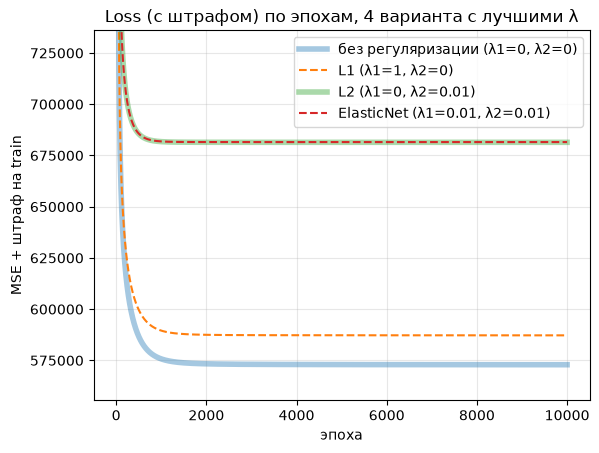

In [12]:
plot_variants(models_lin, "MSE + штраф на train")

### Метрики и веса

In [13]:
rows = {}
for name, model in models_lin.items():
    pred_val = model.predict(X_val_lin)
    pred_test = model.predict(X_test_lin)
    w = np.abs(model.w)

    rows[name] = {
        "λ1": model.l1,
        "λ2": model.l2,
        "RMSE val": rmse(y_val_lin, pred_val),
        "RMSE test": rmse(y_test_lin, pred_test),
        "MAE test": mae(y_test_lin, pred_test),
        "R2 test": r2(y_test_lin, pred_test),
        "Σ|w|": w.sum(),
        "почти нулевых": int(np.sum(w < 0.01 * w.max())),
        "всего весов": len(w),
    }

pd.DataFrame.from_dict(rows, orient="index").round(3)

,λ1,λ2,RMSE val,RMSE test,MAE test,R2 test,Σ|w|,почти нулевых,всего весов
без регуляризации,0.00,0.00,821.788,710.169,542.435,0.846,14609.266,0,29
L1,1.00,0.00,821.381,711.617,544.898,0.846,14003.891,3,29
L2,0.00,0.01,861.572,723.277,561.189,0.841,11427.835,0,29
ElasticNet,0.01,0.01,861.580,723.288,561.201,0.841,11425.541,0,29


## Logistic Regression: Spaceship Titanic

In [14]:
TARGET_LOG = "Transported"
LEARNING_RATE_LOG = 0.1
EPOCHS_LOG = 2000

DROP_LOG = ["PassengerId", "Name", "Cabin"]
SPEND = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]
NUMERIC_LOG = ["Age"] + SPEND
BINARY_LOG = ["CryoSleep", "VIP"]
CATEGORICAL_LOG = ["HomePlanet", "Destination", "Deck", "Side"]

L1_GRID_LOG = [0.0001, 0.001, 0.01, 0.1, 1]
L2_GRID_LOG = [0.0001, 0.001, 0.01, 0.1, 1]


def split_cabin(df):
    parts = df["Cabin"].str.split("/", expand=True)  # палуба/номер/сторона
    return parts[0], parts[2]

In [15]:
class PreprocessorB:
    # импутация, log1p трат, стандартизация числовых, one-hot категорий; статистики — по train

    def __init__(self, numeric, binary, categorical, spend):
        self.numeric = list(numeric)
        self.binary = list(binary)
        self.categorical = list(categorical)
        self.spend = list(spend)

        self.modes_ = {}
        self.medians_ = {}
        self.levels_ = {}
        self.mean_ = None
        self.std_ = None

    def fit(self, df):
        for col in self.binary + self.categorical:
            self.modes_[col] = df[col].mode()[0]

        # медиана трат — только по бодрствующим: у спящих траты всегда 0
        awake = df[df["CryoSleep"] == False]
        for col in self.numeric:
            self.medians_[col] = (awake[col] if col in self.spend else df[col]).median()

        filled = self._impute(df)
        for col in self.categorical:
            self.levels_[col] = np.sort(filled[col].unique())[1:]

        values = self._numeric_matrix(filled)
        self.mean_ = values.mean(axis=0)
        self.std_ = values.std(axis=0)
        return self

    def _impute(self, df):
        # пропуск трат у пассажира в криосне — 0, у бодрствующего — медиана бодрствующих
        out = df.copy()
        for col in self.binary + self.categorical:
            out[col] = out[col].fillna(self.modes_[col])

        in_cryo = out["CryoSleep"] == True
        for col in self.spend:
            fill = pd.Series(np.where(in_cryo, 0.0, self.medians_[col]), index=out.index)
            out[col] = out[col].fillna(fill)

        out["Age"] = out["Age"].fillna(self.medians_["Age"])
        return out

    def _numeric_matrix(self, filled):
        values = filled[self.numeric].to_numpy(dtype=float)
        spend_idx = [self.numeric.index(col) for col in self.spend]
        values[:, spend_idx] = np.log1p(values[:, spend_idx])
        return values

    def transform(self, df):
        filled = self._impute(df)
        numeric = (self._numeric_matrix(filled) - self.mean_) / self.std_
        binary = filled[self.binary].to_numpy(dtype=float)
        dummies = [(filled[col].to_numpy()[:, None] == self.levels_[col][None, :]).astype(float)
                   for col in self.categorical]
        return np.hstack([numeric, binary] + dummies)

In [16]:
df_log = pd.read_csv(DATA_DIR / "spaceship_titanic/train.csv")
deck, side = split_cabin(df_log)
X_df_log = df_log.drop(columns=DROP_LOG + [TARGET_LOG]).assign(Deck=deck, Side=side)
y_log = df_log[TARGET_LOG].to_numpy(dtype=float)

train_idx, val_idx, test_idx = train_val_test_split_own(len(X_df_log), VAL_SIZE, TEST_SIZE, RANDOM_STATE)
prep_log = PreprocessorB(NUMERIC_LOG, BINARY_LOG, CATEGORICAL_LOG, SPEND).fit(X_df_log.iloc[train_idx])

X_train_log = prep_log.transform(X_df_log.iloc[train_idx])
X_val_log = prep_log.transform(X_df_log.iloc[val_idx])
X_test_log = prep_log.transform(X_df_log.iloc[test_idx])
y_train_log, y_val_log, y_test_log = y_log[train_idx], y_log[val_idx], y_log[test_idx]

print(f"train {X_train_log.shape}, val {X_val_log.shape}, test {X_test_log.shape}")

train (5215, 20), val (1739, 20), test (1739, 20)


In [17]:
grids_log = make_grids(L1_GRID_LOG, L2_GRID_LOG)
models_log = {}

for name, pairs in grids_log.items():
    best_log_loss = np.inf
    for l1, l2 in pairs:
        model = LogisticRegression(LEARNING_RATE_LOG, EPOCHS_LOG, l1=l1, l2=l2)
        model.fit(X_train_log, y_train_log)

        val_log_loss = log_loss(y_val_log, model.predict_proba(X_val_log))
        if val_log_loss < best_log_loss:
            best_log_loss = val_log_loss
            models_log[name] = model

### Loss по эпохам

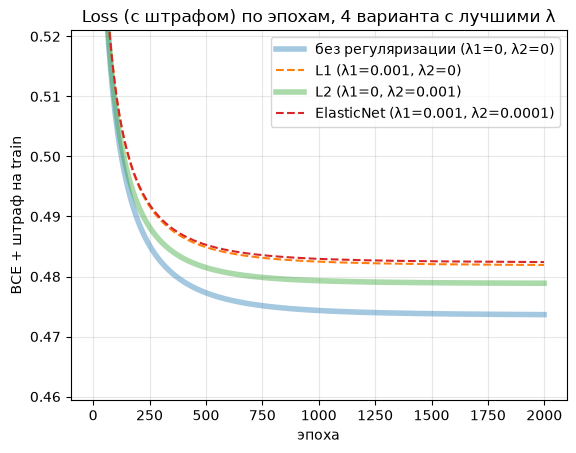

In [18]:
plot_variants(models_log, "BCE + штраф на train")

### Метрики и веса

In [19]:
rows = {}
for name, model in models_log.items():
    pred_test = model.predict(X_test_log)
    w = np.abs(model.w)

    rows[name] = {
        "λ1": model.l1,
        "λ2": model.l2,
        "LogLoss val": log_loss(y_val_log, model.predict_proba(X_val_log)),
        "LogLoss test": log_loss(y_test_log, model.predict_proba(X_test_log)),
        "Accuracy test": accuracy(y_test_log, pred_test),
        "F1 test": f1(y_test_log, pred_test),
        "Σ|w|": w.sum(),
        "почти нулевых": int(np.sum(w < 0.01 * w.max())),
        "всего весов": len(w),
    }

pd.DataFrame.from_dict(rows, orient="index").round(4)

,λ1,λ2,LogLoss val,LogLoss test,Accuracy test,F1 test,Σ|w|,почти нулевых,всего весов
без регуляризации,0.000,0.0000,0.4877,0.4796,0.7780,0.7827,8.6686,1,20
L1,0.001,0.0000,0.4873,0.4809,0.7815,0.7853,7.7263,2,20
L2,0.000,0.0010,0.4875,0.4806,0.7815,0.7853,8.0364,2,20
ElasticNet,0.001,0.0001,0.4873,0.4810,0.7815,0.7853,7.6723,2,20


## Вывод

Регуляризация в обеих моделях почти не повлияла на качество, потому что модели не были переобучены: ошибки на train
и на новых данных близки (линейная RMSE 757 / 822 / 710 на train / val / test, логистическая Accuracy 0.783 / 0.769 / 0.778),
а подбор по validation выбрал самые маленькие λ из сетки. В линейной регрессии L1 осталась на уровне модели без
регуляризации (RMSE val 821.4 против 821.8), а L2 и ElasticNet ухудшили результат (861.6) даже при λ₂ = 0.01.
В логистической регрессии все четыре варианта практически равны (Accuracy test 0.778–0.782).

На весах проявилось различие методов: L2 уменьшила все веса без зануления (у линейной Σ|w| 14 609 → 11 428),
L1 занулила слабые признаки (3 из 29 у линейной, 2 из 20 у логистической), ElasticNet повторил ту составляющую,
у которой λ больше. Регуляризация была бы полезна при переобучении — когда признаков много, данных мало
и на train модель заметно лучше, чем на validation.